*Coursework notebook, LLM Coding Case Study*

## Israel: 2026 Article IV

IMF Country Report No. 26/161. No IMF report on Israel is dated 2024 or 2025, so this is the nearest one, and it reports both years.

**Brief:** Build the pipeline in Google Colab.  
**Done here:** Install the libraries Colab lacks, at fixed versions.

In [1]:
%pip install -q pdfminer.six==20260107 voluptuous==0.16.0 duckdb==2.0.0 langchain-text-splitters==1.1.3 faiss-cpu==1.15.1

**Brief:** Keep the work reproducible.  
**Done here:** Constants live in one block and every step reads them.

In [2]:
import asyncio, hashlib, json, os, re, textwrap, time
from collections import Counter
from pathlib import Path
from typing import Final

import duckdb
import faiss
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import voluptuous as vol
from langchain_text_splitters import RecursiveCharacterTextSplitter
from pdfminer.high_level import extract_pages
from pdfminer.layout import LAParams, LTChar, LTFigure, LTTextContainer, LTTextLine
from sentence_transformers import SentenceTransformer
from transformers import AutoTokenizer

PDF_PATH: Final = "data/IMF_CR_26_161_Israel_2026_Article_IV.pdf"
COUNTRY: Final = "Israel"
FORECAST_YEAR: Final = 2026
WRITER: Final = "gemini-3.5-flash"
JUDGE: Final = "gemini-3.8-flash"
SECRET: Final = "GEMINI_FREE_KEY"
EMBEDDER: Final = "intfloat/e5-base-v2"
TOKENS_PER_CHUNK: Final = 350
TOKENS_SHARED: Final = 50
TOP_K: Final = 6
HEAD_LIMIT: Final = 70.0
FOOT_LIMIT: Final = 735.0
WORD_CAP: Final = 100
PARALLEL_CALLS: Final = 5
TAG_BATCH: Final = 16
RESULTS: Final = Path("results")
CACHE: Final = Path("cache")
RESULTS.mkdir(exist_ok=True)
CACHE.mkdir(exist_ok=True)
FACTS = {}


def keep(name, payload):
    """Save a result as JSON, with DataFrames as lists of records."""
    def plain(item):
        if isinstance(item, pd.DataFrame):
            return json.loads(item.to_json(orient="records"))
        if isinstance(item, np.generic):
            return item.item()
        raise TypeError(type(item))
    (RESULTS / f"{name}.json").write_text(json.dumps(payload, indent=1, default=plain), encoding="utf-8")
    return payload

**Brief:** Use schema-constrained structured output.  
**Done here:** Each reply has a voluptuous rule, and one function turns that rule into the JSON schema Gemini receives.

In [3]:
THEMES = ["Inflation & Prices", "Interest Rates & Credit", "Housing & Real Estate", "Banking Capital & Liquidity", "Sovereign Debt", "Labor Market Dynamics", "Systemic Financial Risk"]
FIELDS = ["gdp_growth_forecast_pct", "headline_inflation_rate_pct", "central_bank_policy_rate_pct", "non_performing_loan_ratio", "unemployment_rate_pct", "tier_1_capital_ratio"]
MARK = vol.All(int, vol.Range(min=1, max=5))
NUMBER_OR_NULL, WHOLE_OR_NULL, WORDS_OR_NULL = vol.Any(None, float, int), vol.Any(None, int), vol.Any(None, str)
need = lambda body: vol.Schema({vol.Required(k): v for k, v in body.items()}, extra=vol.PREVENT_EXTRA)
ITEM = {vol.Required("label"): str, vol.Required("explanation"): str, vol.Required("pdf_page"): int, vol.Required("quote"): str}
READING = {vol.Required(k): v for k, v in {"value": NUMBER_OR_NULL, "year": WHOLE_OR_NULL, "pdf_page": WHOLE_OR_NULL, "evidence": WORDS_OR_NULL, "reason": WORDS_OR_NULL}.items()}

RULE = {
    "summary": need({"summary": str}),
    "marks": need({"consistency": MARK, "completeness": MARK, "factual_alignment": MARK, "faults": [str]}),
    "briefing": need({"bullets": vol.All([{vol.Required("section_id"): str, vol.Required("sentence"): str}], vol.Length(min=6, max=8))}),
    "verdicts": need({"checks": [{vol.Required("number"): int, vol.Required("supported"): bool, vol.Required("reason"): str}]}),
    "tags": need({"tags": [{vol.Required("chunk_id"): str, vol.Required("primary"): vol.In(THEMES + ["none"])}]}),
    "insights": need({"strengths": vol.All([ITEM], vol.Length(min=5, max=7)), "vulnerabilities": vol.All([ITEM], vol.Length(min=5, max=7))}),
    "indicators": need({field: READING for field in FIELDS}),
    "audit": need({"rows": [{vol.Required("field"): vol.In(FIELDS), vol.Required("verdict"): vol.In(["CORRECT", "WRONG", "NOT_FOUND", "CORRECTLY_NULL", "MISSED"]), vol.Required("page_shows"): NUMBER_OR_NULL, vol.Required("reason"): str}]}),
    "picks": need({"picks": vol.All([{vol.Required("label"): str, vol.Required("why"): str}], vol.Length(min=6, max=10))}),
    "answer": need({"answer": str, "citations": [str], "answerable": bool}),
    "answer_marks": need({"faithfulness": MARK, "completeness": MARK, "faithfulness_reason": str, "completeness_reason": str}),
    "rewrites": need({"rewrites": vol.All([str], vol.Length(min=3, max=3))}),
}


def wire_format(node):
    """Translate a voluptuous rule into a JSON schema."""
    if isinstance(node, vol.Schema):
        node = node.schema
    if isinstance(node, dict):
        return {"type": "object", "properties": {str(k): wire_format(v) for k, v in node.items()}, "required": [str(k) for k in node]}
    if isinstance(node, list):
        return {"type": "array", "items": wire_format(node[0])}
    if isinstance(node, vol.All):
        return wire_format(node.validators[0])
    if isinstance(node, vol.In):
        return {"type": "string", "enum": list(node.container)}
    if isinstance(node, vol.Any):
        kinds = [v for v in node.validators if v is not None]
        return {"anyOf": [{"type": "number" if float in kinds else wire_format(kinds[0])["type"]}, {"type": "null"}]}
    return {"type": {str: "string", int: "integer", float: "number", bool: "boolean"}[node]}

**Brief:** Optimise the prompts for each job.  
**Done here:** Each prompt is the docstring of an empty function, tagged with its system instruction.

In [4]:
PROMPTS = {}


def instructs(system):
    def register(fn):
        PROMPTS[fn.__name__] = (system, textwrap.dedent(fn.__doc__).strip())
        return fn
    return register


@instructs("You write section digests of IMF surveillance reports for a central bank reader. Use only the supplied text. Tie each number to its period and unit, and name who holds each view: IMF staff, the authorities or Directors.")
def digest():
    """
    Section: {title}, pages {span}.
    Write one paragraph of 70 to 90 words covering the main assessment, the main risk and the advice given.
    {note}
    TEXT:
    {text}
    """


@instructs("You review digests of IMF reports and mark them from 1 to 5. Be hard to please: a 5 means you traced every claim to the text. Any number with the wrong period or unit, or a view given to the wrong party, limits factual_alignment to 2. Report each fault.")
def mark_digest():
    """
    SOURCE ({title}):
    {text}

    DIGEST:
    {digest}
    """


@instructs("You draft the key messages of a financial stability note. Each bullet is one sentence that states a finding or a judgement about risk.")
def key_messages():
    """
    Write 6 to 8 bullets on the main financial stability findings and the risk assessment of the whole report, using the section digests. Give the section_id behind each.
    {note}
    {digests}
    """


@instructs("You test each claim against the source text. Mark supported as true only when the source states the claim.")
def verify():
    """
    {points}
    """


@instructs("You sort passages from an IMF report by the single financial stability theme each mainly concerns. Use none if no theme applies.")
def sort_themes():
    """
    Themes: {themes}

    {passages}
    """


@instructs("You extract growth drivers and vulnerabilities from IMF reports, and every item must rest on a sentence copied word for word.")
def strengths_and_risks():
    """
    For {country}, list 5 to 7 strengths or growth drivers and 5 to 7 systemic vulnerabilities. For each give a short label, a sentence of explanation, the page in the tag and an exact quote of 8 to 25 words.
    {note}
    {text}
    """


@instructs("You transcribe macro-financial indicators from IMF tables and text into JSON. Copy numbers exactly as printed. When a value is not stated, return null for value, year, pdf_page and evidence, and explain why.")
def read_numbers():
    """
    gdp_growth_forecast_pct: real GDP growth projected for {year}.
    headline_inflation_rate_pct: period average CPI inflation projected for {year}.
    central_bank_policy_rate_pct: the latest policy rate stated by the report.
    non_performing_loan_ratio: nonperforming loans to total gross loans, latest period, not net of provisions.
    unemployment_rate_pct: the unemployment rate projected for {year}.
    tier_1_capital_ratio: regulatory Tier 1 capital to risk-weighted assets, latest period, not to total assets.
    Put the page number from the tag in pdf_page and copy the row or sentence into evidence.

    {text}
    """


@instructs("You audit extracted indicators against source pages. CORRECT means the page shows that value for that definition and period. WRONG means it shows another value. NOT_FOUND means you cannot locate it. CORRECTLY_NULL means null and truly absent. MISSED means null but present. Put the value you see in page_shows.")
def audit_numbers():
    """
    EXTRACTED:
    {extracted}

    PAGES:
    {text}
    """


@instructs("You choose data series that chart a country's macro-financial path.")
def choose_series():
    """
    Choose 6 to 10 rows that together show growth, prices, labour, public finances and bank health. Copy each label exactly.
    {labels}
    """


@instructs("You answer questions on an IMF report only from the numbered passages, citing the ids you used. If they do not contain the answer, set answerable to false and say so.")
def reply():
    """
    QUESTION: {question}

    PASSAGES:
    {context}
    """


@instructs("You grade an answer against its passages. faithfulness 5: every claim is in the passages. completeness 5: the question is fully answered. If the answer declines, give completeness 5 only when the passages truly lack the answer.")
def grade():
    """
    QUESTION: {question}

    PASSAGES:
    {context}

    ANSWER:
    {answer}
    """


@instructs("You rewrite search queries for retrieval from an IMF report.")
def rephrase():
    """
    Rewrite this question in 3 different ways, each using different vocabulary but asking the same thing.
    {question}
    """


print(len(PROMPTS), "prompts")

12 prompts


**Brief:** Keep the LLM layer robust and reproducible.  
**Done here:** Calls run concurrently under a semaphore, retry by hand, and store each reply in DuckDB so a rerun needs no key.

In [5]:
STORE = duckdb.connect(str(CACHE / "replies.duckdb"))
STORE.execute("create table if not exists replies (key varchar primary key, body varchar)")
AUDIT_TRAIL, GATE = [], asyncio.Semaphore(PARALLEL_CALLS)
connection = {"client": None, "key": ""}
RETRYABLE = re.compile(r"429|500|502|503|504|RESOURCE_EXHAUSTED|UNAVAILABLE|timed? ?out|cut off|empty reply", re.I)


def api_key():
    """Read only on a store miss, so a stored rerun never touches the secret."""
    if not connection["key"]:
        try:
            from google.colab import userdata
            connection["key"] = userdata.get(SECRET) or ""
        except Exception:
            connection["key"] = os.environ.get(SECRET, "")
    return connection["key"]


async def gemini(model, system, user, schema, heat):
    if not api_key():
        raise RuntimeError(f"no stored reply and no key in {SECRET}")
    from google import genai
    from google.genai import types
    connection["client"] = connection["client"] or genai.Client(api_key=connection["key"])
    wait = 4.0
    for attempt in range(7):
        began = time.perf_counter()
        try:
            got = await connection["client"].aio.models.generate_content(model=model, contents=user, config=types.GenerateContentConfig(
                system_instruction=system, temperature=heat, max_output_tokens=16384, response_mime_type="application/json", response_json_schema=schema))
            if (got.candidates and "MAX_TOKENS" in str(got.candidates[0].finish_reason)) or not (got.text or "").strip():
                raise RuntimeError("cut off or empty reply")
            use = got.usage_metadata
            return {"text": got.text, "seconds": round(time.perf_counter() - began, 2), "tokens_in": use.prompt_token_count or 0, "tokens_out": use.candidates_token_count or 0}
        except Exception as fault:
            if attempt == 6 or not RETRYABLE.search(str(fault)):
                raise
            await asyncio.sleep(wait)
            wait = min(wait * 2, 90)


async def stored_or_live(step, model, system, user, schema, heat):
    key = hashlib.blake2s(json.dumps([model, system, user, schema, heat], sort_keys=True).encode()).hexdigest()
    found, origin = STORE.execute("select body from replies where key = ?", [key]).fetchall(), "stored"
    if found:
        answer = json.loads(found[0][0])
    else:
        async with GATE:
            answer, origin = await gemini(model, system, user, schema, heat), "live"
        STORE.execute("insert or replace into replies values (?, ?)", [key, json.dumps(answer)])
        STORE.execute("checkpoint")
    AUDIT_TRAIL.append({"step": step, "model": model, "origin": origin, **{k: answer[k] for k in ("seconds", "tokens_in", "tokens_out")}})
    return answer


async def call(step, prompt, kind, test=None, role="writer", **fill):
    """One validated call. A rejected reply is sent back with the reasons, at most twice."""
    system, template = PROMPTS[prompt]
    user, complaints, model = template.format(**fill), [], JUDGE if role == "judge" else WRITER
    for retry in (0, 1, 2):
        message = user + (f"\n\nYour previous reply was rejected: {'; '.join(complaints)}. Send a corrected reply." if complaints else "")
        raw = await stored_or_live(step + ("+fix" if retry else ""), model, system, message, wire_format(RULE[kind]), 0.0 if role == "judge" else 0.25)
        try:
            data = RULE[kind](json.loads(raw["text"]))
        except (json.JSONDecodeError, vol.Invalid) as fault:
            complaints = [f"invalid reply: {str(fault)[:300]}"]
            continue
        complaints = test(data) if test else []
        if not complaints:
            return data
    raise RuntimeError(f"{step}: {complaints}")

**Brief:** Extract the text and clean line breaks, running headers, footers and artifacts.  
**Done here:** pdfminer gives every line its height on the page, so anything outside the limits is dropped.

In [6]:
FLAT = str.maketrans({"\ufb01": "fi", "\ufb02": "fl", "\ufb00": "ff", "\ufb03": "ffi", "\u2018": "'", "\u2019": "'", "\u201c": '"', "\u201d": '"', "\u2013": "-", "\u2014": "-", "\u2010": "-", "\u2011": "-", "\u2212": "-", "\u00ad": "", "\u00a0": " ", "\u2022": "*", "\uf0b7": "*", "\u00bd": ".5", "\u00bc": ".25", "\u00be": ".75"})
NEW_ITEM = re.compile(r"^(?:\d{1,3}\.\s|[A-Z]\.\s|\*\s|\(\w\)\s|Box \d|Figure \d|Table \d)")
CLEANING = Counter()


def text_boxes(layout):
    """Text boxes on a page, including those inside embedded figures, where IMF tables often sit."""
    for item in layout:
        if isinstance(item, LTTextContainer):
            yield item
        elif isinstance(item, LTFigure):
            yield from text_boxes(item)


def lines_on(page):
    """Rows of text as (top, words, left, right), merging boxes that share a height."""
    bits = []
    for box in text_boxes(page):
        for line in box:
            if isinstance(line, LTTextLine) and line.get_text().strip():
                chars = [c for c in line if isinstance(c, LTChar) and c.get_text().strip()]
                if chars:
                    bits.append({"top": page.height - line.y1, "x0": line.x0, "x1": line.x1, "text": re.sub(r"\s+", " ", line.get_text().strip().translate(FLAT)), "size": round(chars[0].size, 1), "bold": "Bold" in chars[0].fontname, "italic": "Italic" in chars[0].fontname})
    bits.sort(key=lambda b: (round(b["top"] / 4), b["x0"]))
    rows = []
    for bit in bits:
        if rows and abs(rows[-1]["top"] - bit["top"]) < 4:
            rows[-1].update(text=f"{rows[-1]['text']} {bit['text']}", x1=max(rows[-1]["x1"], bit["x1"]))
        else:
            rows.append(dict(bit))
    return bits, rows


def glue(rows):
    """Rejoin wrapped lines into paragraphs."""
    out = []
    for row in rows:
        if out and not NEW_ITEM.match(row["text"]) and not (out[-1][1].endswith((".", ":", ";")) and row["top"] - out[-1][2] > 17):
            head = out[-1][1]
            out[-1][1] = (head[:-1] + row["text"]) if head.endswith("-") and row["text"][:1].islower() else f"{head} {row['text']}"
            CLEANING["hyphen breaks joined"] += head.endswith("-") and row["text"][:1].islower()
            CLEANING["wrapped lines joined"] += 1
            out[-1][2] = row["top"]
        else:
            out.append([row["top"], row["text"], row["top"]])
    return [(top, text) for top, text, _ in out]


def titled(bits, number):
    found = []
    for bit in bits:
        if bit["bold"] and bit["size"] >= 12 and len(bit["text"]) > 3 and bit["top"] > HEAD_LIMIT:
            if found and found[-1]["size"] == bit["size"] and bit["top"] - found[-1]["last"] < 30:
                found[-1].update(text=f"{found[-1]['text']} {bit['text']}", last=bit["top"])
            else:
                found.append({"page": number, "size": bit["size"], "top": bit["top"], "last": bit["top"], "text": bit["text"]})
    return found


def read_pdf():
    pages = []
    for number, page in enumerate(extract_pages(PDF_PATH, laparams=LAParams(line_margin=0.3, all_texts=True)), 1):
        bits, rows = lines_on(page)
        inside = [r for r in rows if HEAD_LIMIT - 4 < r["top"] < FOOT_LIMIT]
        CLEANING["rows in header and footer bands removed"] += len(rows) - len(inside)
        table = sum(len(re.findall(r"(?:^| )-?\d[\d,]*\.\d(?= |$)", r["text"])) >= 3 for r in inside) >= 3 and any(re.match(r"Table \d", r["text"]) for r in inside[:3])
        figure = not table and any(re.match(r"Figure \w*\.?\d*", r["text"]) for r in inside[:2])
        if figure:
            kept = [r for r in inside if len(re.findall(r"[A-Za-z]{3,}", r["text"])) >= 5]
            CLEANING["chart labels dropped"] += len(inside) - len(kept)
            inside = kept
        parts = [(r["top"], r["text"]) for r in inside] if table else glue(inside)
        pages.append({"page": number, "kind": "table" if table else "figure" if figure else "prose", "parts": parts, "rows": [r["text"] for r in inside] if table else [], "text": "\n".join(t for _, t in parts), "titles": titled(bits, number)})
    return pages


FACTS["pages"] = read_pdf()
print(Counter(p["kind"] for p in FACTS["pages"]), dict(CLEANING))


def stamped(numbers):
    return "\n\n".join(f"[PAGE {n}]\n{FACTS['pages'][n - 1]['text']}" for n in numbers)

Counter({'prose': 62, 'table': 8, 'figure': 7}) {'rows in header and footer bands removed': 177, 'hyphen breaks joined': 8, 'wrapped lines joined': 2043, 'chart labels dropped': 222}


**Brief:** Find each major chapter or section.  
**Done here:** Headings are recognised by bold type at a large size, and each section ends where the next heading starts.

In [7]:
OMIT = re.compile(r"^(ISRAEL$|CONTENTS|International Monetary Fund|Washington|Approved|Prepared)")
UNSUMMARISED = re.compile(r"^(References|2026 ARTICLE|STAFF REPORT)", re.I)


def split_sections():
    pages = FACTS["pages"]
    first_annex = next(t["page"] for p in pages for t in p["titles"] if t["text"].startswith("Annex I"))
    marks = [t for p in pages for t in p["titles"] if not OMIT.match(t["text"]) and (t["size"] >= 14 or (t["size"] == 13.0 and t["page"] < first_annex) or re.match(r"Statement (by|of)", t["text"]))]
    first_figure = next(p["page"] for p in pages if p["page"] > 29 and re.match(r"Figure \d", p["text"]))
    statement = [{"page": p["page"], "top": top, "text": text, "size": 18.0} for p in pages if p["page"] > first_annex for top, text in p["parts"] if re.match(r"Statement by .*Executive Director", text)][:1]
    marks = sorted(marks + statement + [{"page": first_figure, "top": 0, "text": "Figures and Tables", "size": 18.0}], key=lambda m: (m["page"], m["top"]))
    sections = []
    for mark, stop in zip(marks, marks[1:] + [None]):
        parts = [(n, t) for n in range(mark["page"], (stop["page"] if stop else len(pages)) + 1) for top, t in pages[n - 1]["parts"]
                 if (n > mark["page"] or top >= mark["top"] - 5) and (not stop or n < stop["page"] or top < stop["top"] - 5) and "____" not in t]
        if parts:
            text = "\n\n".join(t for _, t in parts)
            sections.append({"sid": f"S{len(sections) + 1:02d}", "title": mark["text"][:100], "pages": sorted({n for n, _ in parts}), "parts": parts, "text": text, "digest": len(text) > 700 and not UNSUMMARISED.match(mark["text"])})
    return sections


FACTS["sections"] = split_sections()
section_view = pd.DataFrame(FACTS["sections"]).assign(first=lambda d: d.pages.str[0], last=lambda d: d.pages.str[-1], chars=lambda d: d.text.str.len())[["sid", "title", "first", "last", "chars", "digest"]]
section_view

,sid,title,first,last,chars,digest
0,S01,2026 ARTICLE IV CONSULTATION-PRESS RELEASE; ST...,1,2,1681,False
1,S02,IMF Executive Board Concludes 2026 Article IV ...,2,5,7052,True
2,S03,KEY ISSUES,5,7,3807,True
3,S04,CONTEXT-CHALLENGES,9,9,2226,True
4,S05,RECENT ECONOMIC DEVELOPMENTS,9,12,8522,True
5,S06,OUTLOOK AND RISKS,13,17,8181,True
6,S07,POLICY DISCUSSIONS,17,17,541,False
7,S08,A. Restoring Fiscal Buffers Amid Persistently ...,17,21,8171,True
8,S09,B. Advancing the Longstanding Structural Refor...,21,24,7442,True
9,S10,C. Ensuring Price Stability,24,25,2143,True


**Brief:** Make overlapping, token-aware chunks of 300 to 500 tokens with a 50-token overlap.  
**Done here:** A recursive splitter breaks on paragraphs, then sentences, counting with the embedder's tokenizer.

In [8]:
tokenizer = AutoTokenizer.from_pretrained(EMBEDDER, model_max_length=10**6)
splitter = RecursiveCharacterTextSplitter.from_huggingface_tokenizer(tokenizer, chunk_size=TOKENS_PER_CHUNK, chunk_overlap=TOKENS_SHARED, separators=["\n\n", "\n", ". ", " "], add_start_index=True)


def make_chunks():
    chunks = []
    for section in FACTS["sections"]:
        if len(section["text"]) < 200 or UNSUMMARISED.match(section["title"]):
            continue
        offsets, cursor = [], 0
        for number, part in section["parts"]:
            offsets.append((cursor, number))
            cursor += len(part) + 2
        for doc in splitter.create_documents([section["text"]]):
            start, end = doc.metadata["start_index"], doc.metadata["start_index"] + len(doc.page_content)
            on = sorted({n for at, n in offsets if at < end and at >= start} | {max((o for o in offsets if o[0] <= start), default=offsets[0])[1]})
            chunks.append({"sid": section["sid"], "title": section["title"], "pages": on, "tokens": len(tokenizer.encode(doc.page_content, add_special_tokens=False)), "text": doc.page_content})
    for i, chunk in enumerate(chunks, 1):
        chunk["id"] = f"C{i:03d}"
    return chunks


FACTS["chunks"] = make_chunks()
keep("chunks", FACTS["chunks"])
QUERY = duckdb.connect()
chunk_frame = pd.DataFrame(FACTS["chunks"])[["id", "sid", "tokens", "text"]]
QUERY.register("chunk_frame", chunk_frame)
QUERY.sql("select count(*) as chunks, median(tokens) as median_tokens, min(tokens) as least, max(tokens) as most from chunk_frame").df()

,chunks,median_tokens,least,most
0,156,290.0,5,350


**Brief:** Summarise each section in under 100 words, with a second LLM evaluating consistency, completeness and factual alignment.  
**Done here:** All sections run concurrently. Code enforces the limit and tests the figures, and a faulted digest gets one rewrite.

In [9]:
numbers_of = lambda text: set(re.findall(r"\d+(?:\.\d+)?", text.replace(",", "")))
missing_from = lambda claim, source: sorted(numbers_of(claim) - numbers_of(source))
letters = lambda text: re.sub(r"[^a-z0-9]", "", text.lower())
under_cap = lambda data: [] if len(data["summary"].split()) < WORD_CAP else [f"keep it under {WORD_CAP} words"]
sum_marks = lambda m: m["consistency"] + m["completeness"] + m["factual_alignment"]


async def one_digest(section, tail="", note=""):
    text = (await call(f"digest:{section['sid']}{tail}", "digest", "summary", test=under_cap, title=section["title"], span=f"{section['pages'][0]}-{section['pages'][-1]}", text=section["text"], note=note))["summary"]
    marks_given = await call(f"mark:{section['sid']}{tail}", "mark_digest", "marks", role="judge", title=section["title"], text=section["text"], digest=text)
    return text, marks_given, missing_from(text, section["text"])


async def digest_section(section):
    text, given, stray = await one_digest(section)
    record = {"sid": section["sid"], "title": section["title"], "pages": f"{section['pages'][0]}-{section['pages'][-1]}", "first_text": text, "first_marks": [given["consistency"], given["completeness"], given["factual_alignment"]], "first_faults": given["faults"], "first_stray": stray, "rewritten": False}
    if min(record["first_marks"]) < 4 or stray or given["faults"]:
        faults = given["faults"] + [f"{x} is not in the text" for x in stray]
        new_text, new_given, new_stray = await one_digest(section, ":again", "A reviewer found these problems in an earlier draft. Fix them: " + "; ".join(faults) + "\nEarlier draft: " + text)
        if not new_stray and sum_marks(new_given) >= sum_marks(given):
            text, given, stray, record["rewritten"] = new_text, new_given, new_stray, True
    return {**record, "summary": text, "words": len(text.split()), "consistency": given["consistency"], "completeness": given["completeness"], "factual_alignment": given["factual_alignment"], "faults": given["faults"], "stray": stray}


FACTS["digests"] = pd.DataFrame(await asyncio.gather(*[digest_section(s) for s in FACTS["sections"] if s["digest"]])).sort_values("sid", ignore_index=True)
digests = FACTS["digests"]
assert digests.words.max() < WORD_CAP
keep("section_summaries", digests)
print(f"{len(digests)} digests, {digests.words.min()} to {digests.words.max()} words, {int(digests.rewritten.sum())} rewritten")
digests[["sid", "title", "words", "consistency", "completeness", "factual_alignment", "rewritten"]]

24 digests, 79 to 89 words, 10 rewritten


,sid,title,words,consistency,completeness,factual_alignment,rewritten
0,S02,IMF Executive Board Concludes 2026 Article IV ...,85,5,5,5,False
1,S03,KEY ISSUES,87,5,4,5,True
2,S04,CONTEXT-CHALLENGES,80,5,4,5,False
3,S05,RECENT ECONOMIC DEVELOPMENTS,89,5,5,5,False
4,S06,OUTLOOK AND RISKS,84,5,4,5,False
5,S08,A. Restoring Fiscal Buffers Amid Persistently ...,80,5,4,5,False
6,S09,B. Advancing the Longstanding Structural Refor...,83,5,5,5,False
7,S10,C. Ensuring Price Stability,88,5,4,5,True
8,S11,D. Safeguarding Financial Stability,83,5,4,5,False
9,S12,E. Strengthening Financial Integrity,85,5,5,5,True


**Brief:** Generate key bullet points on the financial stability findings and risk assessment.  
**Done here:** Bullets are written from the digests and each is verified against the whole section it names.

In [10]:
BY_SECTION = {s["sid"]: s for s in FACTS["sections"]}
valid_section = lambda data: [f"no section {b['section_id']}" for b in data["bullets"] if b["section_id"] not in BY_SECTION]


async def verify_bullets(bullets):
    points = "\n\n".join(f"POINT {n}: {b['sentence']}\nSOURCE: {BY_SECTION[b['section_id']]['text']}" for n, b in enumerate(bullets, 1))
    return (await call("messages:verify", "verify", "verdicts", role="judge", points=points))["checks"]


async def key_points():
    overview = "\n".join(f"[{r.sid}] {r.title}: {r.summary}" for r in digests.itertuples())
    data = await call("messages", "key_messages", "briefing", test=valid_section, digests=overview, note="")
    checks = await verify_bullets(data["bullets"])
    objections = [f"point {c['number']}: {c['reason']}" for c in checks if not c["supported"]] + [f"point {n}: {x} is not in its section" for n, b in enumerate(data["bullets"], 1) for x in missing_from(b["sentence"], BY_SECTION[b["section_id"]]["text"])]
    if objections:
        data = await call("messages:again", "key_messages", "briefing", test=valid_section, digests=overview, note="Correct or replace these rejected points: " + "; ".join(objections))
        checks = await verify_bullets(data["bullets"])
    return {"bullets": data["bullets"], "checks": checks, "first_objections": objections}


FACTS["messages"] = await key_points()
keep("executive_summary", FACTS["messages"])
for bullet in FACTS["messages"]["bullets"]:
    print(f"* [{bullet['section_id']}] {bullet['sentence']}")

* [S11] IMF staff assess that prudent supervision has supported financial stability, though major risks stem from the real estate sector where bank exposures exceeded half of total credit by early 2025.
* [S21] IMF staff assess Israel's overall risk of sovereign stress as moderate, while projecting public debt to rise to 76.3 percent of GDP by 2035 without fiscal adjustment.
* [S08] IMF staff note that elevated defense spending risks driving public debt to 74 percent of GDP by 2031.
* [S19] IMF staff assess high-likelihood global risks as being dominated by geopolitical tensions, trade protectionism, and disorderly artificial intelligence corrections that threaten financial stability.
* [S23] IMF staff warn that expanding presales and balloon loans heighten financial risks within the real estate sector.
* [S24] IMF staff note that main risks persist in bank resolution as establishing a solvency support and bank resolution funding mechanism remains unimplemented.
* [S03] IMF staff asses

**Brief:** Count occurrences across the seven financial stability themes.  
**Done here:** DuckDB counts term matches with SQL, and the writer labels every chunk for comparison.

In [11]:
VOCABULARY = {
    "Inflation & Prices": r"inflation|disinflation|consumer prices?|CPI|price stability",
    "Interest Rates & Credit": r"policy rates?|interest rates?|credit|lending|yields?|spreads?",
    "Housing & Real Estate": r"housing|real estate|mortgages?|home prices?|construction",
    "Banking Capital & Liquidity": r"banks?|banking|capital|liquidity|NPLs?|nonperforming|non-performing",
    "Sovereign Debt": r"debt|deficits?|sovereign|fiscal rule|borrowing",
    "Labor Market Dynamics": r"labou?r|employment|unemployment|workers?|wages?|Haredi|reservists?",
    "Systemic Financial Risk": r"systemic|financial stability|contagion|stress tests?|macroprudential|FSAP",
}


def sql_hits(pattern):
    return int(QUERY.execute("select coalesce(sum(len(regexp_extract_all(text, ?))), 0) from chunk_frame", [rf"(?i)\b(?:{pattern})\b"]).fetchall()[0][0])


async def tag_batch(start, batch):
    wanted = {c["id"] for c in batch}
    rule = lambda data: [] if {t["chunk_id"] for t in data["tags"]} == wanted else ["label each passage once, by its id"]
    passages = "\n\n".join(f"<{c['id']}> {c['text'][:1000]}" for c in batch)
    return (await call(f"themes:{start:03d}", "sort_themes", "tags", test=rule, themes="; ".join(THEMES), passages=passages))["tags"]


tags = sum(await asyncio.gather(*[tag_batch(i, FACTS["chunks"][i:i + TAG_BATCH]) for i in range(0, len(FACTS["chunks"]), TAG_BATCH)]), [])
tag_count = Counter(t["primary"] for t in tags)
theme_table = pd.DataFrame({"theme": THEMES, "term_matches": [sql_hits(VOCABULARY[t]) for t in THEMES], "chunks_labelled": [tag_count[t] for t in THEMES]})
theme_table["term_share"] = (100 * theme_table.term_matches / theme_table.term_matches.sum()).round(1)
theme_table["label_share"] = (100 * theme_table.chunks_labelled / max(theme_table.chunks_labelled.sum(), 1)).round(1)
FACTS["themes"] = {"table": theme_table, "no_theme": tag_count["none"], "rank_agreement": round(float(theme_table.term_matches.corr(theme_table.chunks_labelled, method="spearman")), 3)}
keep("theme_counts", FACTS["themes"])
print("rank agreement:", FACTS["themes"]["rank_agreement"], "| chunks with no theme:", FACTS["themes"]["no_theme"])
theme_table

rank agreement: 0.741 | chunks with no theme: 51


,theme,term_matches,chunks_labelled,term_share,label_share
0,Inflation & Prices,92,9,10.6,8.6
1,Interest Rates & Credit,96,9,11.1,8.6
2,Housing & Real Estate,113,16,13.1,15.2
3,Banking Capital & Liquidity,208,11,24.0,10.5
4,Sovereign Debt,162,44,18.7,41.9
5,Labor Market Dynamics,149,9,17.2,8.6
6,Systemic Financial Risk,45,7,5.2,6.7


**Brief:** Extract 5 to 7 growth drivers or strengths and 5 to 7 vulnerabilities.  
**Done here:** Every item must carry an exact quote, and code confirms that quote is on the page it names.

In [12]:
async def insights():
    pages = FACTS["pages"]
    read = sorted({n for s in FACTS["sections"] if re.match(r"IMF Executive Board|KEY ISSUES|STAFF APPRAISAL|Annex IV", s["title"]) for n in s["pages"]})
    def quotes_real(data):
        return [f"the quote for {i['label']} is not word for word on page {i['pdf_page']}; quote one sentence of running text, not a table" for kind in ("strengths", "vulnerabilities") for i in data[kind] if not 1 <= i["pdf_page"] <= len(pages) or letters(i["quote"]) not in letters(pages[i["pdf_page"] - 1]["text"])]
    data = await call("insights", "strengths_and_risks", "insights", test=quotes_real, country=COUNTRY, note="", text=stamped(read))
    entries = [("strength", i) for i in data["strengths"]] + [("vulnerability", i) for i in data["vulnerabilities"]]
    points = "\n".join(f"POINT {n} (claimed {kind}): {i['label']}. {i['explanation']} QUOTE: {i['quote']}" for n, (kind, i) in enumerate(entries, 1))
    return {**data, "checks": (await call("insights:verify", "verify", "verdicts", role="judge", points=points))["checks"], "pages_read": read}


FACTS["insights"] = await insights()
keep("strengths_vulnerabilities", FACTS["insights"])
print(sum(c["supported"] for c in FACTS["insights"]["checks"]), "of", len(FACTS["insights"]["checks"]), "supported")
pd.DataFrame([{"kind": k, "label": i["label"], "page": i["pdf_page"]} for k in ("strengths", "vulnerabilities") for i in FACTS["insights"][k]])

3 of 10 supported


,kind,label,page
0,strengths,Economic Resilience,3
1,strengths,High-Tech Leadership,29
2,strengths,Resilient Banking Sector,6
3,strengths,Trade Reform Progress,3
4,strengths,Fiscal Policy Commitment,3
5,vulnerabilities,Military Mobilization Pressures,2
6,vulnerabilities,Real Estate Market Exposure,6
7,vulnerabilities,Demographic Labor Gaps,29
8,vulnerabilities,Rising Fiscal Deficits,29
9,vulnerabilities,Near-Term Inflation Risks,2


**Brief:** Build a local RAG index with dense embeddings and FAISS IndexFlatL2.  
**Done here:** E5 embeddings with its passage and query prefixes, normalised so L2 order matches cosine order.

In [13]:
embedder = SentenceTransformer(EMBEDDER)
passages = [f"passage: {c['title']}. {c['text']}" for c in FACTS["chunks"]]
vector_file = CACHE / f"vectors_{hashlib.blake2s(json.dumps([EMBEDDER, passages]).encode()).hexdigest()[:12]}.npy"
if not vector_file.exists():
    np.save(vector_file, embedder.encode(passages, normalize_embeddings=True, batch_size=16, show_progress_bar=False).astype("float32"))
vectors = np.load(vector_file)
space = faiss.IndexFlatL2(vectors.shape[1])
space.add(vectors)


def retrieve(question, k=TOP_K):
    query = embedder.encode([f"query: {question}"], normalize_embeddings=True).astype("float32")
    distances, ranks = space.search(query, k)
    return [{**FACTS["chunks"][i], "distance": round(float(d), 4)} for d, i in zip(distances[0], ranks[0])]


print(space.ntotal, "vectors of size", space.d)

156 vectors of size 768


**Brief:** Audit the factual accuracy of the extracted numbers.  
**Done here:** Tables are parsed by rule with no model involved, giving an independent value for each indicator.

In [14]:
CELL_TOKEN = re.compile(r"^(?:-?\d[\d,]*(?:\.\d+)?|\.\.\.|\u2026)$")


def table_frame(page):
    years, rows = None, {}
    for row in page["rows"]:
        words = row.split()
        stamps = [w for w in words if re.fullmatch(r"20\d\d(?:Q\d)?", w)]
        if years is None and len(stamps) >= 4:
            years = stamps
            continue
        cells = []
        while words and CELL_TOKEN.match(words[-1]):
            cells.insert(0, words.pop())
        if years and words and len(cells) == len(years):
            rows[re.sub(r"(?: \d/)+$", "", " ".join(words))] = [None if c in ("...", "\u2026") else float(c.replace(",", "")) for c in cells]
    return pd.DataFrame(rows, index=years).T


def page_with(title):
    return next(p for p in FACTS["pages"] if title in p["text"] and p["kind"] == "table")


def cell(frame, starts, column):
    return float(frame.loc[next(x for x in frame.index if x.startswith(starts)), column])


summary_page, soundness_page, long_page = page_with("Selected Economic Indicators, 2024"), page_with("Financial Soundness Indicators"), page_with("Selected Economic Indicators, 2022")
outlook, soundness, history = table_frame(summary_page), table_frame(soundness_page), table_frame(long_page)
latest_bank = soundness.columns[-1]
rate_page = next(p for p in FACTS["pages"] if re.search(r"policy rate[^.]{0,60}to (\d+\.\d+) percent", p["text"]))
ANCHOR = {"gdp_growth_forecast_pct": (cell(outlook, "Real GDP growth", str(FORECAST_YEAR)), summary_page["page"]), "headline_inflation_rate_pct": (cell(outlook, "Inflation (period average", str(FORECAST_YEAR)), summary_page["page"]),
          "central_bank_policy_rate_pct": (float(re.search(r"policy rate[^.]{0,60}to (\d+\.\d+) percent", rate_page["text"])[1]), rate_page["page"]), "non_performing_loan_ratio": (cell(soundness, "Nonperforming loans to total gross", latest_bank), soundness_page["page"]),
          "unemployment_rate_pct": (cell(outlook, "Unemployment", str(FORECAST_YEAR)), summary_page["page"]), "tier_1_capital_ratio": (cell(soundness, "Regulatory Tier I capital to risk", latest_bank), soundness_page["page"])}
pd.DataFrame(ANCHOR, index=["value", "pdf_page"]).T

,value,pdf_page
gdp_growth_forecast_pct,3.50,4.0
headline_inflation_rate_pct,2.30,4.0
central_bank_policy_rate_pct,3.75,24.0
non_performing_loan_ratio,0.60,42.0
unemployment_rate_pct,3.00,4.0
tier_1_capital_ratio,11.50,42.0


**Brief:** Extract the indicators as strictly valid JSON, and capture any that are missing with a fallback.  
**Done here:** The writer reads the table pages and the nearest text. A null must carry a reason, and values are tested with `is None`.

In [15]:
SEARCHES = {"gdp_growth_forecast_pct": "real GDP growth forecast", "headline_inflation_rate_pct": "average inflation forecast", "central_bank_policy_rate_pct": "Bank of Israel policy rate cut", "non_performing_loan_ratio": "nonperforming loans of banks", "unemployment_rate_pct": "unemployment rate outlook", "tier_1_capital_ratio": "bank Tier 1 capital ratio"}
has_reason = lambda data: [f"{f}: null needs a reason" for f in FIELDS if data[f]["value"] is None and not data[f]["reason"]]
to_schema = lambda data: {"country_name": COUNTRY, **{f: (None if data[f]["value"] is None else float(data[f]["value"])) for f in FIELDS}}
read_list = sorted({summary_page["page"], soundness_page["page"]} | {hit["pages"][0] for q in SEARCHES.values() for hit in retrieve(q, 2)})
extraction = await call("indicators", "read_numbers", "indicators", test=has_reason, year=FORECAST_YEAR, text=stamped(read_list))
audit_rows = (await call("indicators:audit", "audit_numbers", "audit", role="judge", extracted=json.dumps(to_schema(extraction)), text=stamped(read_list)))["rows"]
verdict_of = {r["field"]: r for r in audit_rows}
indicator_view = pd.DataFrame([{"field": f, "value": extraction[f]["value"], "year": extraction[f]["year"], "page": extraction[f]["pdf_page"], "table_value": ANCHOR[f][0], "table_page": ANCHOR[f][1], "code_agrees": extraction[f]["value"] == ANCHOR[f][0], "judge": verdict_of.get(f, {}).get("verdict"), "judge_saw": verdict_of.get(f, {}).get("page_shows"), "evidence": extraction[f]["evidence"], "fallback_reason": extraction[f]["reason"]} for f in FIELDS])
FACTS["record"] = to_schema(extraction)
keep("indicators", FACTS["record"])
keep("indicators_provenance", {"pages_read": read_list, "rows": indicator_view})
print(json.dumps(FACTS["record"], indent=1))
indicator_view[["field", "value", "year", "page", "table_value", "code_agrees", "judge"]]

{
 "country_name": "Israel",
 "gdp_growth_forecast_pct": 3.5,
 "headline_inflation_rate_pct": 2.3,
 "central_bank_policy_rate_pct": 3.75,
 "non_performing_loan_ratio": 0.6,
 "unemployment_rate_pct": 3.0,
 "tier_1_capital_ratio": 11.5
}


,field,value,year,page,table_value,code_agrees,judge
0,gdp_growth_forecast_pct,3.50,2026,4,3.50,True,CORRECT
1,headline_inflation_rate_pct,2.30,2026,4,2.30,True,CORRECT
2,central_bank_policy_rate_pct,3.75,2026,28,3.75,True,CORRECT
3,non_performing_loan_ratio,0.60,2025,42,0.60,True,CORRECT
4,unemployment_rate_pct,3.00,2026,4,3.00,True,CORRECT
5,tier_1_capital_ratio,11.50,2025,42,11.50,True,CORRECT


**Brief:** Show evidence that numbers were checked by a person.  
**Done here:** Values read from the PDF by eye, used only in this comparison.

In [16]:
EYE = {"gdp_growth_forecast_pct": (3.5, 4), "headline_inflation_rate_pct": (2.3, 4), "central_bank_policy_rate_pct": (3.75, 24), "non_performing_loan_ratio": (0.6, 42), "unemployment_rate_pct": (3.0, 4), "tier_1_capital_ratio": (11.5, 42)}
eye_view = indicator_view[["field", "value", "table_value", "judge"]].assign(read_by_eye=lambda d: d.field.map(lambda f: EYE[f][0]), pdf_page=lambda d: d.field.map(lambda f: EYE[f][1]))
eye_view["match"] = eye_view.value == eye_view.read_by_eye
keep("hand_checks", eye_view)
eye_view

,field,value,table_value,judge,read_by_eye,pdf_page,match
0,gdp_growth_forecast_pct,3.50,3.50,CORRECT,3.50,4,True
1,headline_inflation_rate_pct,2.30,2.30,CORRECT,2.30,4,True
2,central_bank_policy_rate_pct,3.75,3.75,CORRECT,3.75,24,True
3,non_performing_loan_ratio,0.60,0.60,CORRECT,0.60,42,True
4,unemployment_rate_pct,3.00,3.00,CORRECT,3.00,4,True
5,tier_1_capital_ratio,11.50,11.50,CORRECT,11.50,42,True


**Brief:** Test the fallback path.  
**Done here:** All six values exist in the report, so the extractor also reads the press release alone, where bank ratios are absent.

In [17]:
press = [p["page"] for p in FACTS["pages"] if p["page"] in (2, 3)]
trial = await call("indicators:press_only", "read_numbers", "indicators", test=has_reason, year=FORECAST_YEAR, text=stamped(press))
fallback_view = pd.DataFrame([{"field": f, "value": trial[f]["value"], "reason": trial[f]["reason"]} for f in FIELDS])
keep("fallback_drill", fallback_view)
print(int(fallback_view.value.isna().sum()), "of", len(FIELDS), "fields fell back")
fallback_view

5 of 6 fields fell back


,field,value,reason
0,gdp_growth_forecast_pct,3.5,None
1,headline_inflation_rate_pct,NaN,The document notes that inflation is expected ...
2,central_bank_policy_rate_pct,NaN,The document mentions a moderately tight monet...
3,non_performing_loan_ratio,NaN,The document mentions that banks remain well-c...
4,unemployment_rate_pct,NaN,The document discusses labor market pressures ...
5,tier_1_capital_ratio,NaN,The document notes that banks are well-capital...


**Brief:** Identify trends over time suitable for plotting.  
**Done here:** The writer chooses rows from the parsed tables, and `pd.melt` reshapes the parsed values.

In [18]:
frames_by_table = {"history": history, "soundness": soundness}
row_names = [label for frame in frames_by_table.values() for label in frame.index]
only_real = lambda data: [f"unknown label: {p['label']}" for p in data["picks"] if p["label"] not in row_names]
picks = (await call("trends", "choose_series", "picks", test=only_real, labels="\n".join(row_names)))["picks"]
wanted_rows = {p["label"] for p in picks}
trend_long = pd.concat([frame.loc[[x for x in frame.index if x in wanted_rows]].rename_axis("series").reset_index().melt(id_vars="series", var_name="period", value_name="value").assign(table=name) for name, frame in frames_by_table.items()], ignore_index=True).dropna(subset="value")
keep("time_series", {"picks": picks, "long": trend_long})
trend_long.groupby("series").agg(first=("period", "min"), last=("period", "max"), points=("value", "size"))

,first,last,points
series,,,
Nonperforming loans to total gross loans,2018,2025Q3,8
"Overall CPI (percent change, average)",2022,2031,10
Overall balance,2022,2031,10
Public Debt,2022,2031,10
Real GDP,2022,2031,10
Regulatory capital to risk-weighted assets,2018,2025Q3,8
Unemployment rate (percent),2022,2031,10


**Brief:** Answer factual queries from retrieved context and evaluate faithfulness and completeness.  
**Done here:** Ten questions plus one the report cannot answer, checked by the judge and against pages I read by hand.

In [19]:
QUESTION_SET = [
    ("Q01", "What real GDP growth does staff project for 2026 and 2027?", [4, 13]),
    ("Q02", "What does staff advise on the fiscal deficit given higher defense spending?", [17, 18]),
    ("Q03", "Why did the Bank of Israel cut its policy rate and to what level?", [24, 28]),
    ("Q04", "How strong are Israeli banks in capital, asset quality and profitability?", [10, 30, 42]),
    ("Q05", "What does staff recommend to raise employment among Haredi men and Arab women?", [20, 21, 22]),
    ("Q06", "What risks arise from housing finance in Israel?", [65, 66, 67, 68]),
    ("Q07", "What does the sovereign risk and debt sustainability assessment conclude?", [56, 58, 59, 60]),
    ("Q08", "What is the assessment of Israel's external position?", [49, 50]),
    ("Q09", "How could an energy price shock affect the economy?", [16]),
    ("Q10", "What does the report say about financial integrity and anti-money laundering?", [27, 30]),
    ("Q11", "What share of Israel's electricity is generated by nuclear power?", []),
]


async def answer_from(hits, qid, question, gold, tail=""):
    context = "\n\n".join(f"[{h['id']}] (pages {h['pages']}) {h['text']}" for h in hits)
    allowed = {h["id"] for h in hits}
    citations_ok = lambda data: [f"unknown citation {c}" for c in data["citations"] if c not in allowed] + ([] if data["citations"] or not data["answerable"] else ["cite at least one passage"])
    data = await call(f"rag:{qid}{tail}", "reply", "answer", test=citations_ok, question=question, context=context)
    marks_given = await call(f"rag:{qid}{tail}:mark", "grade", "answer_marks", role="judge", question=question, context=context, answer=data["answer"])
    pool, cited = {p for h in hits for p in h["pages"]}, {p for h in hits if h["id"] in data["citations"] for p in h["pages"]}
    return {"qid": qid, "question": question, "answer": data["answer"], "answerable": data["answerable"], "citations": data["citations"], "pages_retrieved": sorted(pool), "gold_pages": gold, "gold_recall": round(len(pool & set(gold)) / len(gold), 3) if gold else None,
            "cited_gold": bool(cited & set(gold)) if gold else None, "stray": missing_from(re.sub(r"\bC\d{3}\b", "", data["answer"]), " ".join(h["text"] for h in hits) + " " + question), **marks_given}


rag_view = pd.DataFrame(await asyncio.gather(*[answer_from(retrieve(q), qid, q, gold) for qid, q, gold in QUESTION_SET])).sort_values("qid", ignore_index=True)
keep("rag_answers", rag_view)
print(f"page recall {rag_view.gold_recall.mean():.3f} | faithfulness {rag_view.faithfulness.mean():.2f} | completeness {rag_view.completeness.mean():.2f}")
rag_view[["qid", "gold_recall", "cited_gold", "answerable", "faithfulness", "completeness", "stray"]]

page recall 0.625 | faithfulness 5.00 | completeness 5.00


,qid,gold_recall,cited_gold,answerable,faithfulness,completeness,stray
0,Q01,0.000,False,True,5,5,[]
1,Q02,1.000,True,True,5,5,[]
2,Q03,0.500,True,True,5,5,[]
3,Q04,0.667,True,True,5,5,[]
4,Q05,0.333,True,True,5,5,[]
5,Q06,0.750,True,True,5,5,[5]
6,Q07,0.500,True,True,5,5,[]
7,Q08,1.000,True,True,5,5,[]
8,Q09,1.000,True,True,5,5,[]
9,Q10,0.500,True,True,5,5,[]


In [20]:
for row in rag_view.itertuples():
    print(f"{row.qid} {row.question}\n   {row.answer}\n")

Q01 What real GDP growth does staff project for 2026 and 2027?
   Under staff's baseline, real GDP growth is projected at 3.5 percent in 2026 and is expected to rise to 4.4 percent in 2027 as the direct impact of the war fades.

Q02 What does staff advise on the fiscal deficit given higher defense spending?
   Given higher defense spending and fiscal pressures, staff advises the authorities to aim to contain the deficit within the 4.9 percent of GDP ceiling by enforcing strict spending controls, reprioritizing non-priority spending, and introducing new revenue measures if necessary. If defense spending exceeds allocations, staff notes it could be accommodated within the overall envelope through contingency reserves. Over the medium term, staff advises that fiscal consolidation should steadily continue, with additional measures required beyond 2027 to lower the central government deficit to around 2.5 percent of GDP over the following three years, prioritizing revenue measures.

Q03 Why

**Brief:** Extension: compare Multi-Query RAG with single-query RAG on measurable metrics.  
**Done here:** Three rewrites per question, with the four result lists interleaved in turn until six different chunks are chosen.

In [21]:
def interleave(lists, k=TOP_K):
    """Take the best remaining chunk from each list in turn."""
    chosen, seen = [], set()
    for rank in range(max(map(len, lists))):
        for ranked in lists:
            if rank < len(ranked) and ranked[rank]["id"] not in seen and len(chosen) < k:
                seen.add(ranked[rank]["id"])
                chosen.append(ranked[rank])
    return chosen


async def multi_query(qid, question, gold):
    rewrites = (await call(f"rewrite:{qid}", "rephrase", "rewrites", question=question))["rewrites"]
    began = time.perf_counter()
    hits = interleave([retrieve(q, TOP_K) for q in [question] + rewrites])
    return {"rewrites": rewrites, "search_seconds": round(time.perf_counter() - began, 3), **await answer_from(hits, qid, question, gold, ":multi")}


multi_view = pd.DataFrame(await asyncio.gather(*[multi_query(*q) for q in QUESTION_SET])).sort_values("qid", ignore_index=True)
paired = pd.concat([rag_view.assign(arm="single query"), multi_view.assign(arm="multi query")], ignore_index=True)
scored = paired.dropna(subset="gold_recall")
comparison = paired.groupby("arm", sort=False).agg(faithfulness=("faithfulness", "mean"), completeness=("completeness", "mean"), stray=("stray", lambda s: int(sum(map(bool, s))))).join(scored.groupby("arm").agg(page_recall=("gold_recall", "mean"), cited_gold=("cited_gold", lambda s: s.astype(float).mean()))).round(3)
keep("extension_multiquery", {"table": comparison.reset_index(), "per_question": paired})
comparison

,faithfulness,completeness,stray,page_recall,cited_gold
arm,,,,,
single query,5.0,5.0,1,0.625,0.9
multi query,5.0,5.0,1,0.575,0.9


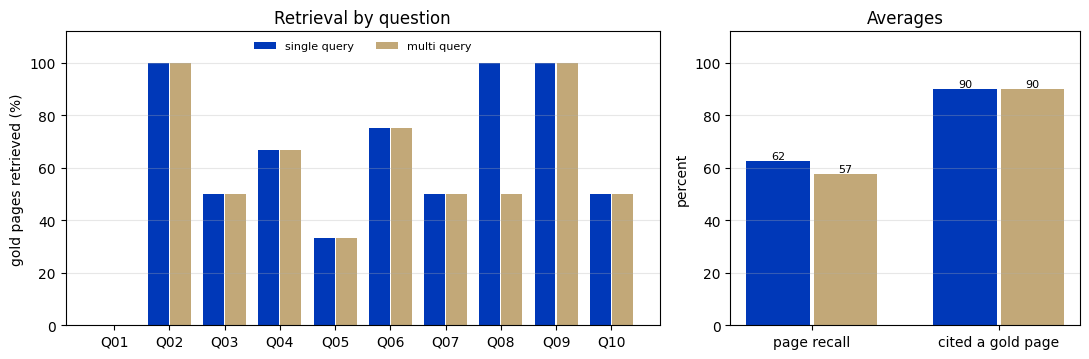

In [22]:
long_recall = scored.melt(id_vars=["qid", "arm"], value_vars=["gold_recall"], value_name="recall")
SAND, DEEP, TEAL = "#C2A878", "#0038B8", "#1B998B"
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.7), gridspec_kw={"width_ratios": [1.7, 1]})
for shift, (arm, part) in zip((-.2, .2), long_recall.groupby("arm", sort=False)):
    left.bar(np.arange(len(part)) + shift, part.recall * 100, width=.38, color=DEEP if arm == "single query" else SAND, label=arm)
left.set(xticks=range(10), xticklabels=[q[0] for q in QUESTION_SET[:10]], ylim=(0, 112), ylabel="gold pages retrieved (%)", title="Retrieval by question")
left.legend(frameon=False, ncol=2, loc="upper center", fontsize=8)
left.grid(axis="y", alpha=.3)
measures = comparison[["page_recall", "cited_gold"]].T * 100
x = np.arange(2)
for shift, arm, hue in ((-.18, "single query", DEEP), (.18, "multi query", SAND)):
    right.bar_label(right.bar(x + shift, measures[arm], width=.34, color=hue), fmt="%.0f", fontsize=8)
right.set(xticks=x, xticklabels=["page recall", "cited a gold page"], ylim=(0, 112), ylabel="percent", title="Averages")
right.grid(axis="y", alpha=.3)
fig.tight_layout()
fig.savefig(RESULTS / "extension.png", dpi=300, facecolor="white")
plt.show()

**Brief:** Show an executive dashboard of at least four plots with model diagnostics, using `pd.melt`, saved at 300 dpi or higher.  
**Done here:** A ticker strip of indicators above five charts and the key messages.

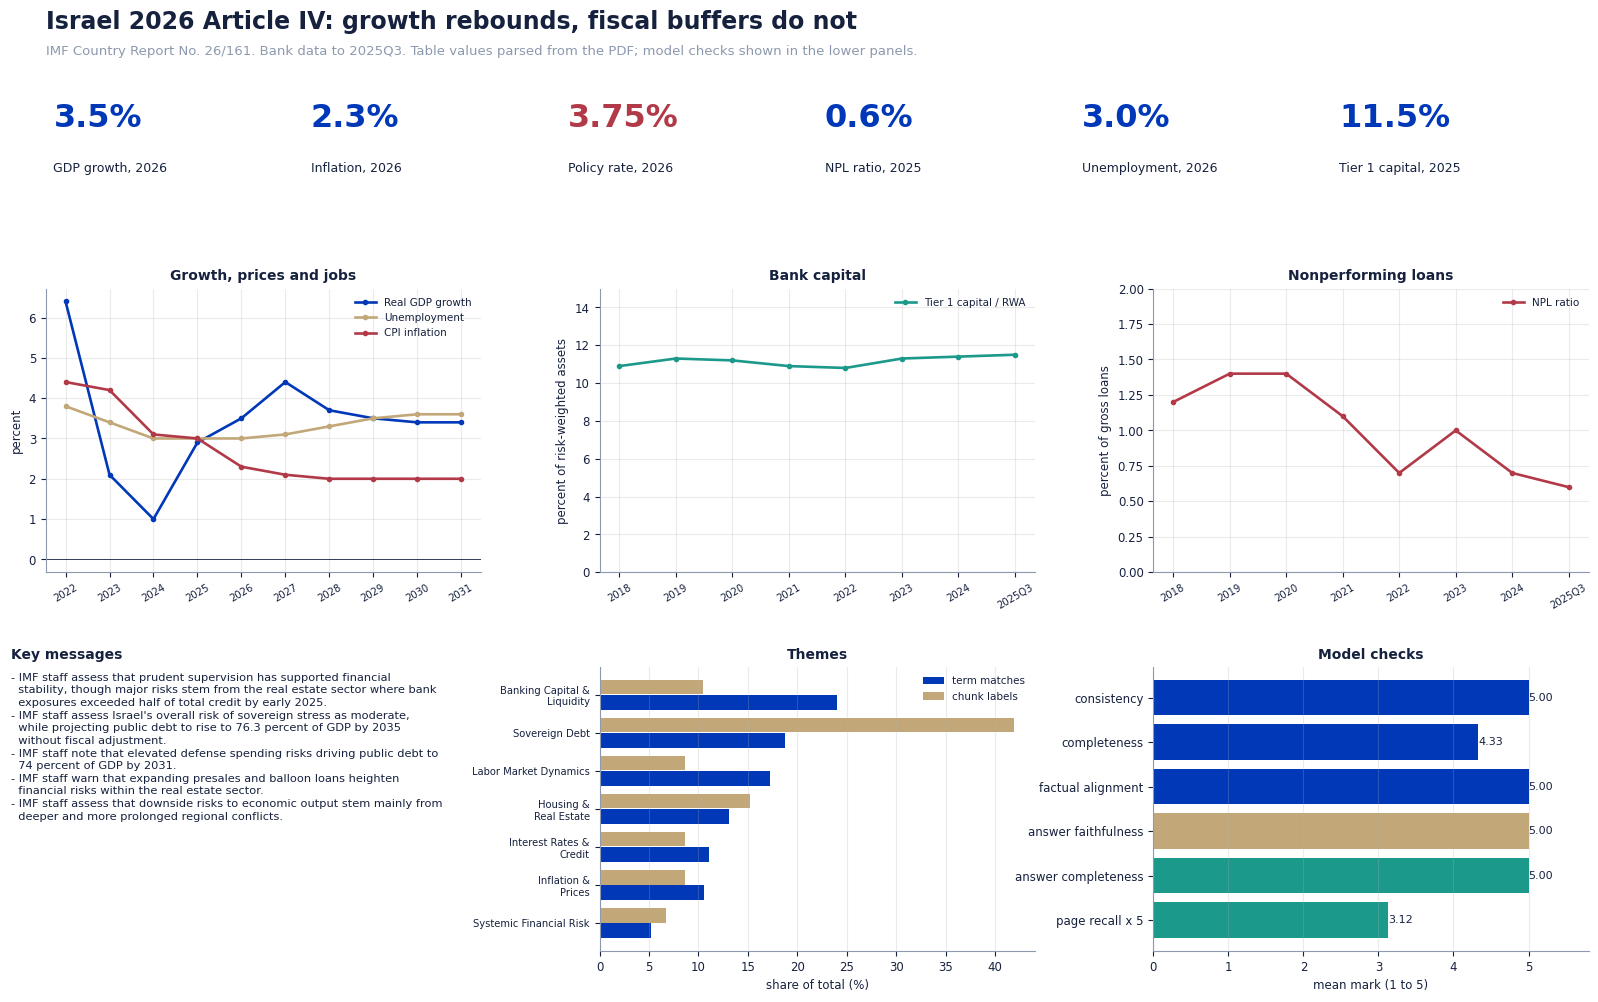

In [23]:
INK, BLUE, GOLD, GREEN, RUST, MIST = "#16213E", "#0038B8", "#C2A878", "#1B998B", "#B23A48", "#8D99AE"
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 8.5, "axes.titlesize": 10, "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MIST, "text.color": INK, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK})
TICKER = {"gdp_growth_forecast_pct": "GDP growth", "headline_inflation_rate_pct": "Inflation", "central_bank_policy_rate_pct": "Policy rate", "non_performing_loan_ratio": "NPL ratio", "unemployment_rate_pct": "Unemployment", "tier_1_capital_ratio": "Tier 1 capital"}
named = lambda frame, starts: next(x for x in frame.index if x.startswith(starts))


def tidy_long(frame, names):
    picked = frame.loc[list(names)].rename(index=names).rename_axis("series").reset_index().melt(id_vars="series", var_name="period", value_name="percent").dropna()
    picked["percent"] = picked.percent.astype(float)
    return picked


def plot_lines(axis, data, colours):
    for name, part in data.groupby("series", sort=False):
        axis.plot(part.period, part.percent, color=colours[name], lw=1.9, marker="o", ms=3, label=name)
    axis.grid(alpha=.25)
    axis.tick_params(axis="x", labelsize=7.2, rotation=30)
    axis.legend(frameon=False, fontsize=7.5)


macro_rows = tidy_long(history, {named(history, "Real GDP"): "Real GDP growth", named(history, "Unemployment"): "Unemployment", named(history, "Overall CPI (percent change, average)"): "CPI inflation"})
fig = plt.figure(figsize=(16.5, 10.3), facecolor="white")
grid = fig.add_gridspec(3, 6, height_ratios=[.42, 1.1, 1.1], hspace=.42, wspace=.75, left=.05, right=.985, top=.91, bottom=.07)
fig.text(.05, .965, "Israel 2026 Article IV: growth rebounds, fiscal buffers do not", fontsize=17, fontweight="bold")
fig.text(.05, .94, "IMF Country Report No. 26/161. Bank data to 2025Q3. Table values parsed from the PDF; model checks shown in the lower panels.", color=MIST, fontsize=9.5)
strip = fig.add_subplot(grid[0, :])
strip.axis("off")
for i, (field, name) in enumerate(TICKER.items()):
    value = FACTS["record"][field]
    period = indicator_view.set_index("field").year[field]
    strip.text(i / 6 + .005, .62, "n/a" if value is None else f"{value:.2f}%" if round(value, 1) != value else f"{value:.1f}%", fontsize=23, fontweight="bold", color=RUST if field == "central_bank_policy_rate_pct" else BLUE, transform=strip.transAxes)
    strip.text(i / 6 + .005, .2, f"{name}, {int(period)}", fontsize=9, transform=strip.transAxes)
growth = fig.add_subplot(grid[1, :2])
plot_lines(growth, macro_rows, {"Real GDP growth": BLUE, "Unemployment": GOLD, "CPI inflation": RUST})
growth.axhline(0, color=INK, lw=.6)
growth.set(title="Growth, prices and jobs", ylabel="percent")
capital = fig.add_subplot(grid[1, 2:4])
plot_lines(capital, tidy_long(soundness, {named(soundness, "Regulatory Tier I capital to risk"): "Tier 1 capital / RWA"}), {"Tier 1 capital / RWA": GREEN})
capital.set(title="Bank capital", ylabel="percent of risk-weighted assets", ylim=(0, 15))
bad_loans = fig.add_subplot(grid[1, 4:])
plot_lines(bad_loans, tidy_long(soundness, {named(soundness, "Nonperforming loans to total gross"): "NPL ratio"}), {"NPL ratio": RUST})
bad_loans.set(title="Nonperforming loans", ylabel="percent of gross loans", ylim=(0, 2))
words = fig.add_subplot(grid[2, :2])
words.axis("off")
held = [b for n, b in enumerate(FACTS["messages"]["bullets"], 1) if {c["number"]: c["supported"] for c in FACTS["messages"]["checks"]}.get(n)]
words.set_title("Key messages", loc="left", x=-.08)
words.text(-.08, .98, "\n".join("\n".join(textwrap.wrap(b["sentence"], 76, initial_indent="- ", subsequent_indent="  ")) for b in held[:5]), va="top", fontsize=8.2, linespacing=1.33, transform=words.transAxes)
ring = fig.add_subplot(grid[2, 2:4])
shares = FACTS["themes"]["table"].melt(id_vars="theme", value_vars=["term_share", "label_share"], var_name="method", value_name="share")
order = FACTS["themes"]["table"].sort_values("term_share").theme.tolist()
for shift, method, hue, label in ((-.2, "term_share", BLUE, "term matches"), (.2, "label_share", GOLD, "chunk labels")):
    ring.barh(np.arange(len(order)) + shift, shares[shares.method == method].set_index("theme").loc[order].share, height=.38, color=hue, label=label)
ring.set(yticks=range(len(order)), yticklabels=[t.replace(" & ", " &\n") for t in order], xlabel="share of total (%)", title="Themes")
ring.tick_params(axis="y", labelsize=7.2)
ring.legend(frameon=False, fontsize=7.5)
ring.grid(axis="x", alpha=.25)
check = fig.add_subplot(grid[2, 4:])
averages = pd.melt(digests[["consistency", "completeness", "factual_alignment"]], var_name="measure", value_name="mark").groupby("measure", sort=False).mark.mean()
extra = pd.Series({"answer faithfulness": rag_view.faithfulness.mean(), "answer completeness": rag_view.completeness.mean(), "page recall x 5": rag_view.gold_recall.mean() * 5})
all_checks = pd.concat([averages.rename(lambda x: x.replace("_", " ")), extra])
bars = check.barh(all_checks.index[::-1], all_checks.values[::-1], color=[GREEN, GREEN, GOLD, BLUE, BLUE, BLUE][:len(all_checks)])
check.bar_label(bars, fmt="%.2f", fontsize=8)
check.set(xlim=(0, 5.8), xlabel="mean mark (1 to 5)", title="Model checks")
check.grid(axis="x", alpha=.25)
fig.savefig(RESULTS / "dashboard.png", dpi=300, facecolor="white")
plt.show()

**Brief:** Keep a full record of the run.  
**Done here:** The call log and prompts are saved, and the store is flushed to disk.

In [24]:
trail = pd.DataFrame(AUDIT_TRAIL)
keep("call_log", {"writer": WRITER, "judge": JUDGE, "calls": len(trail), "live": int((trail.origin == "live").sum()), "stored": int((trail.origin == "stored").sum()), "fixes": int(trail.step.str.endswith("+fix").sum()), "rows": trail})
keep("prompt_book", {name: {"system": s, "template": t} for name, (s, t) in PROMPTS.items()})
STORE.execute("checkpoint")
print(f"{len(trail)} calls: {int((trail.origin == 'live').sum())} live, {int((trail.origin == 'stored').sum())} stored, {int(trail.step.str.endswith('+fix').sum())} fixed")
trail.groupby("model").agg(calls=("step", "size"), seconds=("seconds", "mean"), tokens_in=("tokens_in", "sum"), tokens_out=("tokens_out", "sum")).round(2)

148 calls: 0 live, 148 stored, 1 fixed


,calls,seconds,tokens_in,tokens_out
model,,,,
gemini-3.5-flash,86,9.91,187235,16889
gemini-3.8-flash,62,7.33,158422,6539
